# Step 5. EDA & Visualization — Overall Arrival Delay Distribution

## Objective

This notebook examines the overall distribution of arrival delays for flights departing from New York City airports in 2013.

We explore the shape of the distribution, compare the mean and median, examine early and late arrivals, and identify extreme delays.

This analysis helps explain why average arrival delays may differ from typical arrival delays and provides background for the statistical models in the next milestone.

## 1. Load & Validate Data

Load the cleaned dataset prepared in Step 3 and verify that arrival delay values are available.

The analysis includes all flights with valid arrival delay observations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

data_path = Path("data/cleaned/analysis_ready_flights.csv")
fig_dir = Path("results/figures")
table_dir = Path("results/tables")

fig_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

analysis = pd.read_csv(data_path)

assert "arr_delay" in analysis.columns
assert analysis["arr_delay"].notna().all()

delay_data = analysis.copy()
delays = delay_data["arr_delay"]

print("Dataset shape:", delay_data.shape)
print("Total flights:", f"{len(delay_data):,}")
print("Missing arrival delays:", delays.isna().sum())

display(delay_data[["arr_delay"]].head())

Dataset shape: (327346, 34)
Total flights: 327,346
Missing arrival delays: 0


,arr_delay
0,11.0
1,20.0
2,33.0
3,-18.0
4,-25.0


## 2. Overall Descriptive Statistics

Calculate the mean, median, standard deviation, minimum, maximum, quartiles, and skewness of arrival delays.

Comparing the mean and median helps identify whether unusually large delays influence the overall average.

In [2]:
overall_stats = pd.DataFrame({
    "Statistic": [
        "Total Flights",
        "Mean",
        "Median",
        "Standard Deviation",
        "Minimum",
        "25th Percentile",
        "75th Percentile",
        "90th Percentile",
        "95th Percentile",
        "99th Percentile",
        "Maximum",
        "Skewness"
    ],
    "Value": [
        len(delays),
        delays.mean(),
        delays.median(),
        delays.std(),
        delays.min(),
        delays.quantile(0.25),
        delays.quantile(0.75),
        delays.quantile(0.90),
        delays.quantile(0.95),
        delays.quantile(0.99),
        delays.max(),
        delays.skew()
    ]
})

display(overall_stats.round(2))

,Statistic,Value
0,Total Flights,327346.00
1,Mean,6.90
2,Median,-5.00
3,Standard Deviation,44.63
4,Minimum,-86.00
5,25th Percentile,-17.00
6,75th Percentile,14.00
7,90th Percentile,52.00
8,95th Percentile,91.00
9,99th Percentile,190.00


## 3. Arrival Delay Distribution

Visualize the distribution of arrival delays using a histogram.

The first figure shows the full range of arrival delays, including extreme values.

The second figure focuses on the range from −60 to 180 minutes to make the main distribution easier to examine. The focused view does not change the underlying dataset.

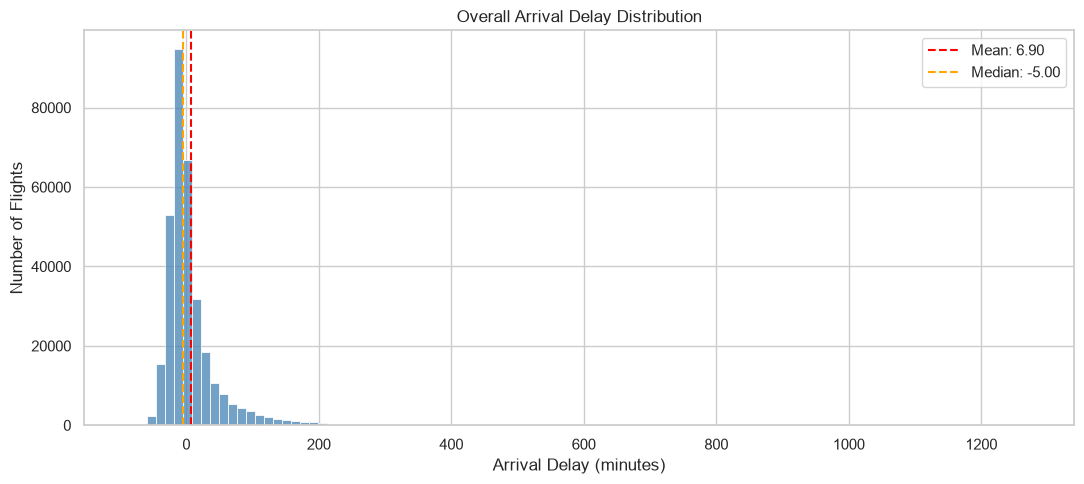

In [3]:
fig, ax = plt.subplots(figsize=(11, 5))

sns.histplot(
    delays,
    bins=100,
    color="steelblue",
    ax=ax
)

ax.axvline(
    delays.mean(),
    color="red",
    linestyle="--",
    label=f"Mean: {delays.mean():.2f}"
)

ax.axvline(
    delays.median(),
    color="orange",
    linestyle="--",
    label=f"Median: {delays.median():.2f}"
)

ax.set(
    title="Overall Arrival Delay Distribution",
    xlabel="Arrival Delay (minutes)",
    ylabel="Number of Flights"
)

ax.legend()
plt.tight_layout()

plt.savefig(
    fig_dir / "overall_arrival_delay_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

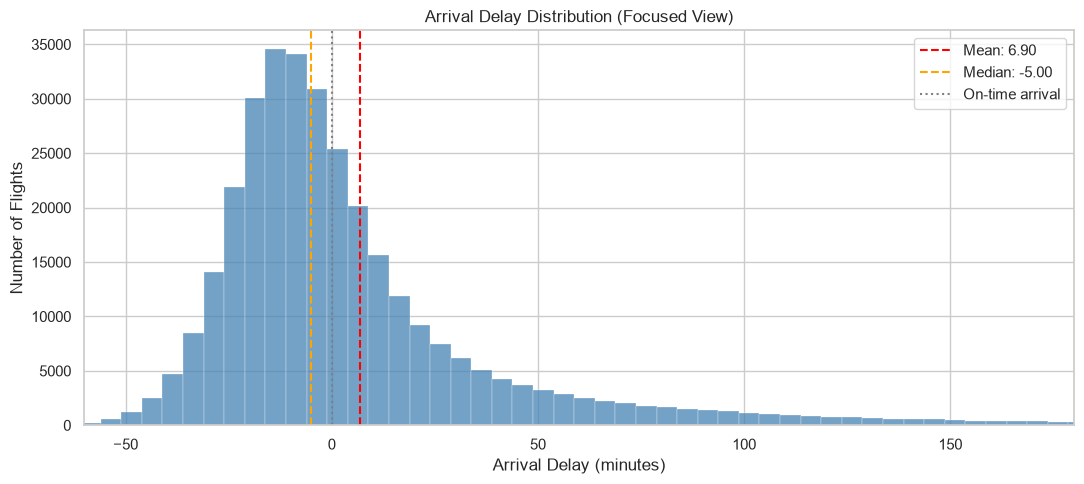

In [4]:
fig, ax = plt.subplots(figsize=(11, 5))

sns.histplot(
    delays,
    binwidth=5,
    color="steelblue",
    ax=ax
)

ax.set_xlim(-60, 180)

ax.axvline(
    delays.mean(),
    color="red",
    linestyle="--",
    label=f"Mean: {delays.mean():.2f}"
)

ax.axvline(
    delays.median(),
    color="orange",
    linestyle="--",
    label=f"Median: {delays.median():.2f}"
)

ax.axvline(
    0,
    color="gray",
    linestyle=":",
    label="On-time arrival"
)

ax.set(
    title="Arrival Delay Distribution (Focused View)",
    xlabel="Arrival Delay (minutes)",
    ylabel="Number of Flights"
)

ax.legend()
plt.tight_layout()

plt.savefig(
    fig_dir / "overall_arrival_delay_focused.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 4. Early, On-Time, and Late Arrivals

Classify flights based on their arrival delay values:

- Early: arrival delay below 0 minutes
- On Time: arrival delay equal to 0 minutes
- Late: arrival delay above 0 minutes

This classification describes arrival timing relative to the scheduled arrival time.

In [5]:
arrival_order = ["Early", "On Time", "Late"]

delay_data["arrival_status"] = np.select(
    [
        delays < 0,
        delays == 0,
        delays > 0
    ],
    arrival_order,
    default="Unknown"
)

arrival_status_stats = (
    delay_data["arrival_status"]
    .value_counts()
    .reindex(arrival_order, fill_value=0)
    .to_frame("Flights")
)

arrival_status_stats["Percentage"] = (
    arrival_status_stats["Flights"] / len(delay_data) * 100
)

display(arrival_status_stats.round(2))

assert arrival_status_stats["Flights"].sum() == len(delay_data)

,Flights,Percentage
arrival_status,,
Early,188933,57.72
On Time,5409,1.65
Late,133004,40.63


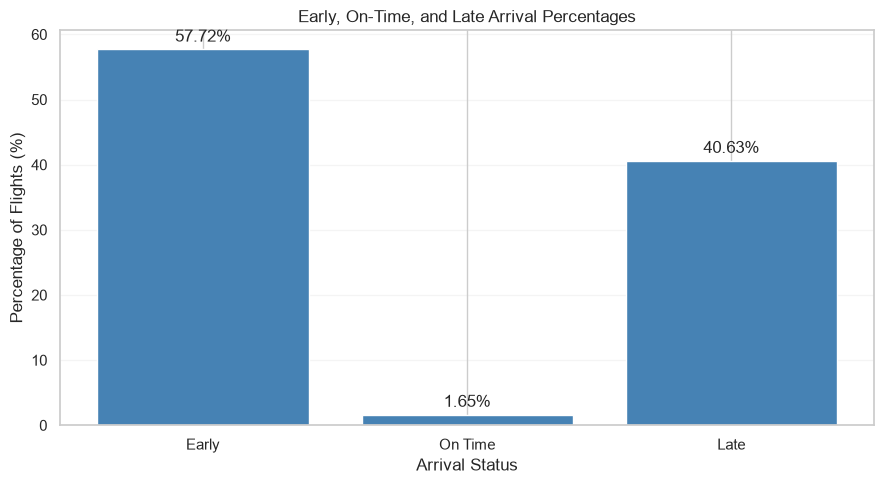

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    arrival_status_stats.index,
    arrival_status_stats["Percentage"],
    color="steelblue"
)

ax.bar_label(bars, fmt="%.2f%%", padding=3)

ax.set(
    title="Early, On-Time, and Late Arrival Percentages",
    xlabel="Arrival Status",
    ylabel="Percentage of Flights (%)"
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    fig_dir / "overall_arrival_status.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 5. Arrival Delay Severity

Classify flights into mutually exclusive arrival delay categories.

- Early or On Time: 0 minutes or less
- 1–15 Minutes Late
- 16–60 Minutes Late
- 61–120 Minutes Late
- More Than 120 Minutes Late

These categories help describe the frequency of different delay severities.

In [7]:
severity_order = [
    "Early or On Time",
    "1-15 Minutes Late",
    "16-60 Minutes Late",
    "61-120 Minutes Late",
    "Over 120 Minutes Late"
]

delay_data["delay_severity"] = pd.cut(
    delays,
    bins=[-np.inf, 0, 15, 60, 120, np.inf],
    labels=severity_order
)

severity_stats = (
    delay_data["delay_severity"]
    .value_counts()
    .reindex(severity_order, fill_value=0)
    .to_frame("Flights")
)

severity_stats["Percentage"] = (
    severity_stats["Flights"] / len(delay_data) * 100
)

display(severity_stats.round(2))

assert severity_stats["Flights"].sum() == len(delay_data)

,Flights,Percentage
delay_severity,,
Early or On Time,194342,59.37
1-15 Minutes Late,55374,16.92
16-60 Minutes Late,49841,15.23
61-120 Minutes Late,17755,5.42
Over 120 Minutes Late,10034,3.07


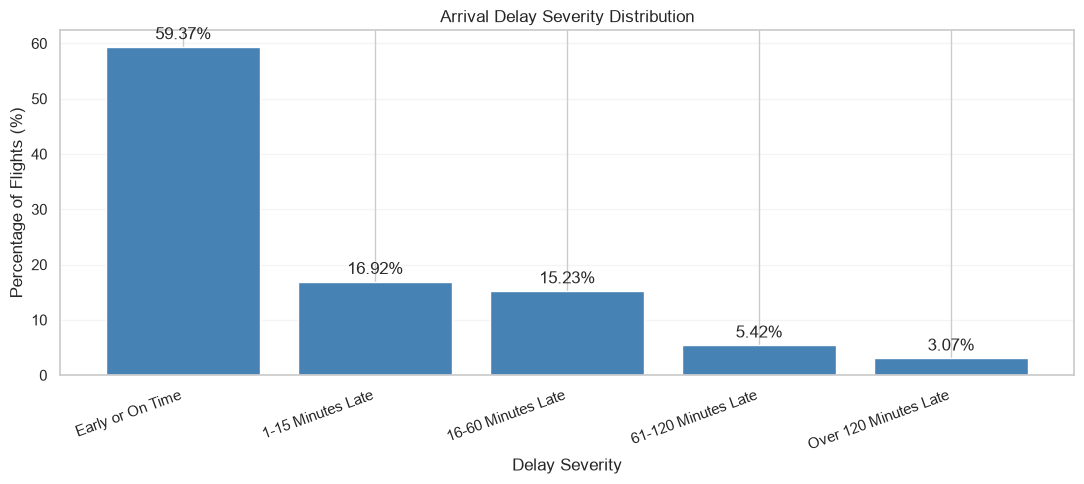

In [8]:
fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.bar(
    severity_stats.index,
    severity_stats["Percentage"],
    color="steelblue"
)

ax.bar_label(bars, fmt="%.2f%%", padding=3)

ax.set(
    title="Arrival Delay Severity Distribution",
    xlabel="Delay Severity",
    ylabel="Percentage of Flights (%)"
)

plt.xticks(rotation=20, ha="right")

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    fig_dir / "overall_arrival_delay_severity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6. Extreme Delays and Outliers

Examine unusually large arrival delays using the interquartile range (IQR) method.

The IQR method identifies observations outside 1.5 times the interquartile range.

These observations are flagged for analysis but are not automatically considered data errors or removed.

We also calculate the percentages of flights delayed more than 15, 60, 120, and 180 minutes.

In [9]:
q1 = delays.quantile(0.25)
q3 = delays.quantile(0.75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_mask = (
    (delays < lower_bound)
    | (delays > upper_bound)
)

outlier_count = outlier_mask.sum()
outlier_pct = outlier_mask.mean() * 100

print(f"Q1: {q1:.2f}")
print(f"Q3: {q3:.2f}")
print(f"IQR: {iqr:.2f}")

print(f"\nLower bound: {lower_bound:.2f}")
print(f"Upper bound: {upper_bound:.2f}")

print(f"\nIQR outliers: {outlier_count:,}")
print(f"IQR outlier percentage: {outlier_pct:.2f}%")

print("\nNote: Outliers are retained in the dataset.")

Q1: -17.00
Q3: 14.00
IQR: 31.00

Lower bound: -63.50
Upper bound: 60.50

IQR outliers: 27,880
IQR outlier percentage: 8.52%

Note: Outliers are retained in the dataset.


In [10]:
thresholds = [0, 15, 60, 120, 180]

threshold_stats = pd.DataFrame({
    "Threshold_Minutes": thresholds,
    "Flights": [
        (delays > t).sum()
        for t in thresholds
    ],
    "Percentage": [
        (delays > t).mean() * 100
        for t in thresholds
    ]
})

display(threshold_stats.round(2))

,Threshold_Minutes,Flights,Percentage
0,0,133004,40.63
1,15,77630,23.71
2,60,27789,8.49
3,120,10034,3.07
4,180,3843,1.17


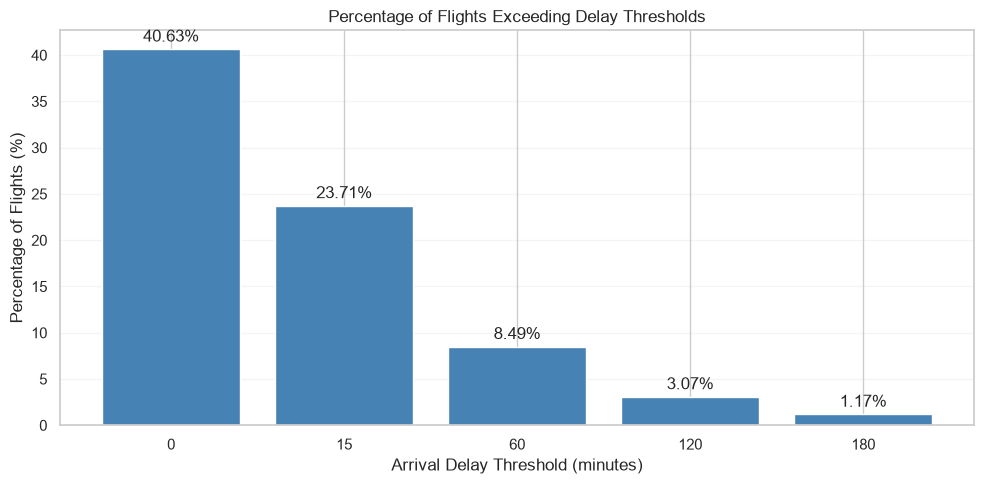

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    threshold_stats["Threshold_Minutes"].astype(str),
    threshold_stats["Percentage"],
    color="steelblue"
)

ax.bar_label(bars, fmt="%.2f%%", padding=3)

ax.set(
    title="Percentage of Flights Exceeding Delay Thresholds",
    xlabel="Arrival Delay Threshold (minutes)",
    ylabel="Percentage of Flights (%)"
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    fig_dir / "overall_arrival_delay_thresholds.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 7. Sensitivity of the Mean to Extreme Delays

Compare the original mean arrival delay with means calculated after excluding flights above selected positive delay thresholds.

This sensitivity analysis examines how unusually large delays affect the overall average.

The original dataset remains unchanged, and all observations are retained for subsequent analyses.

In [12]:
sensitivity_results = [
    {
        "Scenario": "All Flights",
        "Flights": len(delays),
        "Mean": delays.mean(),
        "Median": delays.median()
    }
]

for cutoff in [180, 120, 60]:
    subset = delays[delays <= cutoff]

    sensitivity_results.append({
        "Scenario": f"Exclude Delays > {cutoff} Min",
        "Flights": len(subset),
        "Mean": subset.mean(),
        "Median": subset.median()
    })

sensitivity_stats = pd.DataFrame(sensitivity_results)

sensitivity_stats["Excluded_Flights"] = (
    len(delays) - sensitivity_stats["Flights"]
)

display(sensitivity_stats.round(2))

,Scenario,Flights,Mean,Median,Excluded_Flights
0,All Flights,327346,6.90,-5.0,0
1,Exclude Delays > 180 Min,323503,4.02,-5.0,3843
2,Exclude Delays > 120 Min,317312,1.26,-6.0,10034
3,Exclude Delays > 60 Min,299557,-3.71,-7.0,27789


## 8. Save Results

Export the overall descriptive statistics, arrival status distribution, delay severity distribution, delay thresholds, and sensitivity analysis.

All visualizations are saved for use in the final project report.

In [13]:
overall_stats.round(4).to_csv(
    table_dir / "overall_arrival_delay_statistics.csv",
    index=False
)

arrival_status_stats.round(2).to_csv(
    table_dir / "overall_arrival_status.csv",
    index_label="arrival_status"
)

severity_stats.round(2).to_csv(
    table_dir / "overall_arrival_delay_severity.csv",
    index_label="delay_severity"
)

threshold_stats.round(2).to_csv(
    table_dir / "overall_arrival_delay_thresholds.csv",
    index=False
)

sensitivity_stats.round(2).to_csv(
    table_dir / "overall_arrival_delay_sensitivity.csv",
    index=False
)

print("All overall arrival delay analysis tables saved successfully!")

All overall arrival delay analysis tables saved successfully!


In [14]:
print("=== OVERALL ARRIVAL DELAY EDA SUMMARY ===")

print(f"\nTotal flights: {len(delays):,}")
print(f"Mean arrival delay: {delays.mean():.2f} minutes")
print(f"Median arrival delay: {delays.median():.2f} minutes")
print(f"Standard deviation: {delays.std():.2f} minutes")
print(f"Minimum delay: {delays.min():.0f} minutes")
print(f"Maximum delay: {delays.max():.0f} minutes")
print(f"Skewness: {delays.skew():.4f}")

print("\nArrival Status:")
display(arrival_status_stats.round(2))

print("\nDelay Severity:")
display(severity_stats.round(2))

print("\nDelay Thresholds:")
display(threshold_stats.round(2))

print("\nIQR Outliers:")
print(f"Count: {outlier_count:,}")
print(f"Percentage: {outlier_pct:.2f}%")

print("\nSensitivity Analysis:")
display(sensitivity_stats.round(2))

=== OVERALL ARRIVAL DELAY EDA SUMMARY ===

Total flights: 327,346
Mean arrival delay: 6.90 minutes
Median arrival delay: -5.00 minutes
Standard deviation: 44.63 minutes
Minimum delay: -86 minutes
Maximum delay: 1272 minutes
Skewness: 3.7168

Arrival Status:


,Flights,Percentage
arrival_status,,
Early,188933,57.72
On Time,5409,1.65
Late,133004,40.63



Delay Severity:


,Flights,Percentage
delay_severity,,
Early or On Time,194342,59.37
1-15 Minutes Late,55374,16.92
16-60 Minutes Late,49841,15.23
61-120 Minutes Late,17755,5.42
Over 120 Minutes Late,10034,3.07



Delay Thresholds:


,Threshold_Minutes,Flights,Percentage
0,0,133004,40.63
1,15,77630,23.71
2,60,27789,8.49
3,120,10034,3.07
4,180,3843,1.17



IQR Outliers:
Count: 27,880
Percentage: 8.52%

Sensitivity Analysis:


,Scenario,Flights,Mean,Median,Excluded_Flights
0,All Flights,327346,6.90,-5.0,0
1,Exclude Delays > 180 Min,323503,4.02,-5.0,3843
2,Exclude Delays > 120 Min,317312,1.26,-6.0,10034
3,Exclude Delays > 60 Min,299557,-3.71,-7.0,27789


## 9. Key Findings and Limitations

### Key Findings

The overall mean arrival delay was 6.90 minutes, while the median was −5 minutes. This difference suggests that unusually large positive delays increased the average.

The arrival delay distribution was strongly right-skewed (skewness = 3.7168), with values ranging from −86 to 1,272 minutes.

Most flights arrived early or on time (59.37%). Specifically, 57.72% arrived early, 1.65% arrived exactly on time, and 40.63% arrived late.

Approximately 23.71% of flights arrived more than 15 minutes late, 8.49% arrived more than 60 minutes late, and 3.07% arrived more than 120 minutes late.

The IQR method identified 27,880 observations (8.52%) as statistical outliers. These observations were retained because unusually long delays may represent actual flight operations rather than data errors.

The sensitivity analysis showed that extreme positive delays had a substantial influence on the overall mean. Excluding flights delayed more than 180 minutes reduced the mean from 6.90 to 4.02 minutes. Excluding flights delayed more than 120 minutes further reduced the mean to 1.26 minutes.

Overall, most flights arrived early or on time, but a relatively small proportion of flights with severe delays substantially increased the average arrival delay.

### Limitations

This analysis only includes flights departing from New York City airports in 2013, so the findings may not represent current flight operations.

The arrival delay distribution is strongly right-skewed and contains extreme positive values. These characteristics may affect statistical methods that are sensitive to outliers and distributional assumptions.

The IQR method identifies statistically unusual observations, but it does not determine whether those observations are data errors.

The sensitivity analysis excluded large positive delays to examine their influence on the mean. These results should not replace the original statistics based on all valid flights.

This analysis describes the overall arrival delay distribution but does not identify which factors are associated with delays.

### Data Preparation and Quality Notes

This analysis uses the cleaned flight dataset prepared in Step 3, containing 327,346 flights.

Flights with missing arrival delay values were excluded during data cleaning.

Arrival delay was measured in minutes. Negative values indicate early arrivals, zero indicates an arrival exactly on schedule, and positive values indicate late arrivals.

Flights were classified into mutually exclusive arrival delay severity categories. Delay thresholds of more than 15, 60, 120, and 180 minutes were also examined.

The IQR method was used to identify potential outliers, but no observations were removed from the primary analysis.

Sensitivity analyses were conducted separately to evaluate the influence of extreme positive delays on the mean.